# Fraud Detection – Modeling

This notebook trains and evaluates several classification models to predict credit card fraud.
We use the features selected based on Random Forest feat

## 1. Load libraries and data

In [1]:
import sys
import os

# get the root of the projext (search 'src' folder)
current_dir = os.path.dirname(os.path.abspath("__file__"))
root_dir = current_dir
while not os.path.exists(os.path.join(root_dir, "src")):
    root_dir = os.path.dirname(root_dir)

# Add root to sys.path
sys.path.append(root_dir)

print("Root directory added to sys.path:", root_dir)



Root directory added to sys.path: c:\Users\migue\Desktop\New_repo\fraud_detection


In [2]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV

from src.preprocessing import clean_data
from src.modeling import train_logistic, train_random_forest, train_svm
from src.evaluation import evaluate_model, plot_roc

# Load dataset
df = pd.read_csv("../data/raw/creditcard.csv")

# Clean dataset


df = clean_data(df)

# Separate target and features
X = df.drop("Class", axis=1)
y = df["Class"]

# Train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 2. Select Top Features from Random Forest

In [3]:

# Quick RF to get feature importances
rf_tmp = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)
rf_tmp.fit(X_train, y_train)

importances = pd.Series(rf_tmp.feature_importances_, index=X_train.columns)
top_features = importances.sort_values(ascending=False).head(10).index.tolist()

# Reduce datasets to top features
X_train_top = X_train[top_features]
X_test_top = X_test[top_features]

top_features

['V14', 'V4', 'V10', 'V12', 'V17', 'V3', 'V11', 'V16', 'V2', 'V7']

# 3. Scale Numeric Features 
Important for SVM and Logistic Regression

In [4]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_top)
X_test_scaled = scaler.transform(X_test_top)

# 4. Train models

In [5]:

FAST_MODE = False  # cahnge to False to final training

# --- Parameters by mode ---
if FAST_MODE:
    rf_n_estimators = 50
    rf_max_depth = 10
    lr_max_iter = 200
else:
    rf_n_estimators = 200
    rf_max_depth = None
    lr_max_iter = 1000

# -------------------------------
# Logistic Regression
# -------------------------------
log_model = LogisticRegression(
    solver='saga',     # faster to big datasets
    max_iter=lr_max_iter
)
log_model.fit(X_train_scaled, y_train)
print("Logistic Regression trained.")

# -------------------------------
# Random Forest
# -------------------------------
rf_model = RandomForestClassifier(
    n_estimators=rf_n_estimators,
    max_depth=rf_max_depth,
    n_jobs=-1,         # uses all cpu cores
    random_state=42
)
rf_model.fit(X_train_top, y_train)
print("Random Forest trained.")

# -------------------------------
# SVM (LinearSVC + CalibratedClassifierCV)
# -------------------------------

linear_svc = LinearSVC(max_iter=5000 if FAST_MODE else 10000)
svm_model = CalibratedClassifierCV(linear_svc)  # allow to predict probabilities
svm_model.fit(X_train_scaled, y_train)
print("SVM trained.")


Logistic Regression trained.
Random Forest trained.
SVM trained.


# 5. Evaluate models

=== Logistic Regression ===
Accuracy: 0.9991046662687406
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.82      0.61      0.70        98

    accuracy                           1.00     56962
   macro avg       0.91      0.81      0.85     56962
weighted avg       1.00      1.00      1.00     56962

Confusion Matrix:
 [[56851    13]
 [   38    60]]


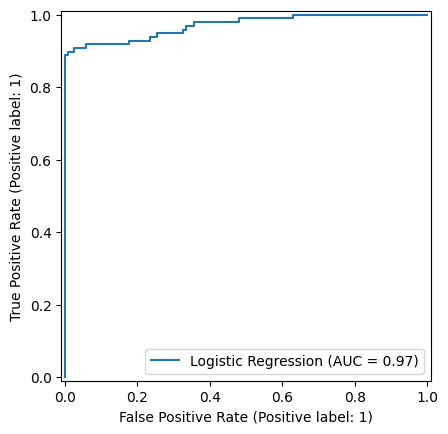


=== Random Forest ===
Accuracy: 0.9996664442961974
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.95      0.85      0.90        98

    accuracy                           1.00     56962
   macro avg       0.98      0.92      0.95     56962
weighted avg       1.00      1.00      1.00     56962

Confusion Matrix:
 [[56860     4]
 [   15    83]]


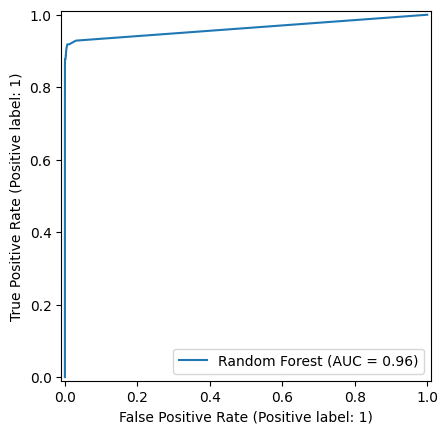


=== SVM ===
Accuracy: 0.9990695551420246
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.82      0.59      0.69        98

    accuracy                           1.00     56962
   macro avg       0.91      0.80      0.84     56962
weighted avg       1.00      1.00      1.00     56962

Confusion Matrix:
 [[56851    13]
 [   40    58]]


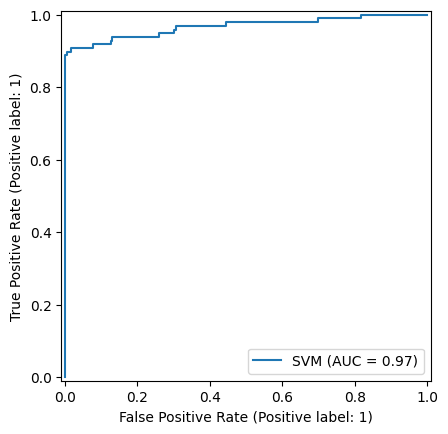

In [6]:
# Logistic Regression
print("=== Logistic Regression ===")
evaluate_model(log_model, X_test_scaled, y_test)
plot_roc(log_model, X_test_scaled, y_test, name="Logistic Regression")

# Random Forest
print("\n=== Random Forest ===")
evaluate_model(rf_model, X_test_top, y_test)
plot_roc(rf_model, X_test_top, y_test, name="Random Forest")

# SVM
print("\n=== SVM ===")
evaluate_model(svm_model, X_test_scaled, y_test)
plot_roc(svm_model, X_test_scaled, y_test, name="SVM")

# 6. Compatariton of models

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Function to get metrics of specific model
def get_metrics(model, X_test, y_test):
    y_pred = model.predict(X_test)

    if hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X_test)[:, 1]
        roc_auc = roc_auc_score(y_test, y_prob)
    else:
        roc_auc = None

    return {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc
    }


In [9]:
results = []

results.append({
    "Model": "Logistic Regression",
    **get_metrics(log_model, X_test_scaled, y_test)
})

results.append({
    "Model": "Random Forest",
    **get_metrics(rf_model, X_test_top, y_test)
})

results.append({
    "Model": "SVM",
    **get_metrics(svm_model, X_test_scaled, y_test)
})

In [12]:

# plot results in dataframe
results_df = pd.DataFrame(results)
results_df


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.999105,0.821918,0.612245,0.701754,0.970408
1,Random Forest,0.999666,0.954023,0.846939,0.897297,0.962819
2,SVM,0.999070,0.816901,0.591837,0.686391,0.967322


# Conclusions — Modeling

In this project, three different machine learning models were trained and evaluated for the fraud detection task:

- Logistic Regression  
- Random Forest  
- Support Vector Machine (SVM)

Due to the strong class imbalance in the dataset, accuracy is not sufficient by itself and must be interpreted together with recall, precision, F1-score and ROC-AUC.

---

## Model Comparison

- **Logistic Regression** achieved the highest **ROC-AUC**, which means it is good at separating fraudulent and non-fraudulent transactions overall.  
  However, its **recall is relatively low**, so many fraud cases are not detected when using the default threshold.

- **Random Forest** obtained the **best recall and F1-score**, detecting a significantly higher number of fraudulent transactions.  
  Although its ROC-AUC is slightly lower than Logistic Regression, it provides a better balance between detecting fraud and avoiding false alarms.

- **SVM** showed competitive ROC-AUC results but similar recall limitations to Logistic Regression, making it less suitable for this use case.

---

## Final Model Choice

For fraud detection, **recall is especially important**, since missing a fraudulent transaction usually has a higher cost than flagging a legitimate one.

Based on this, **Random Forest is selected as the best-performing model**, as it detects more fraud cases while maintaining strong overall performance.

Logistic Regression remains a useful baseline model and could potentially improve its recall by tuning the decision threshold.

---

## Key Takeaway

This analysis highlights the importance of choosing evaluation metrics aligned with the business objective.  
Even if a model has a high ROC-AUC, it may not be the best option if it fails to detect enough fraud cases in practice.
